In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



In [2]:
# 1. Load data (change file name if yours is different)
df = pd.read_csv("IMDb Movies India.csv", encoding="latin-1")
print(df.shape)
print(df.isnull().sum())

(15509, 10)
Name           0
Year         528
Duration    8269
Genre       1877
Rating      7590
Votes       7589
Director     525
Actor 1     1617
Actor 2     2384
Actor 3     3144
dtype: int64


In [3]:
#2. Cleaning: rating is the target, so drop rows without it
df = df.dropna(subset=["Rating"]).copy()
df["Year"] = pd.to_numeric(df["Year"].astype(str).str.extract(r"(\d{4})")[0])
df["Duration"] = pd.to_numeric(df["Duration"].astype(str).str.extract(r"(\d+)")[0])
df["Votes"] = pd.to_numeric(df["Votes"].astype(str).str.replace(",", ""), errors="coerce")
for c in ["Genre", "Director", "Actor 1", "Actor 2", "Actor 3"]:
    df[c] = df[c].fillna("Unknown")

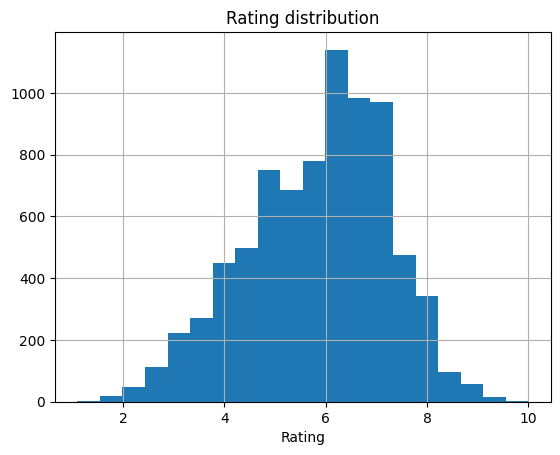

In [4]:
#3. Quick EDA
df["Rating"].hist(bins=20)
plt.title("Rating distribution")
plt.xlabel("Rating")
plt.show()

In [5]:
#4. Genre -> multi-hot columns (keep only the 15 most common)
genres = df["Genre"].str.get_dummies(sep=", ")
genres = genres[genres.sum().nlargest(15).index]
genres.columns = ["G_" + c for c in genres.columns]
df = pd.concat([df, genres], axis=1)

In [6]:
#5. Train/test split BEFORE target encoding (avoids data leakage)
train, test = train_test_split(df, test_size=0.2, random_state=42)
train, test = train.copy(), test.copy()

In [7]:
#6. Target encoding for Director and Actors (mean rating from train only)
global_mean = train["Rating"].mean()
for c in ["Director", "Actor 1", "Actor 2", "Actor 3"]:
    means = train.groupby(c)["Rating"].mean()
    train[c + "_enc"] = train[c].map(means)
    test[c + "_enc"] = test[c].map(means).fillna(global_mean)

In [8]:
#7. Feature list
features = (["Year", "Duration", "Votes"]
            + [c + "_enc" for c in ["Director", "Actor 1", "Actor 2", "Actor 3"]]
            + list(genres.columns))
for f in features:
    med = train[f].median()
    train[f] = train[f].fillna(med)
    test[f] = test[f].fillna(med)

X_train, y_train = train[features], train["Rating"]
X_test, y_test = test[features], test["Rating"]

In [9]:
#8. Models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"\n{name}")
    print("MAE :", round(mean_absolute_error(y_test, pred), 3))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("R2  :", round(r2_score(y_test, pred), 3))


Linear Regression
MAE : 0.912
RMSE: 1.173
R2  : 0.26

Random Forest
MAE : 0.911
RMSE: 1.196
R2  : 0.231


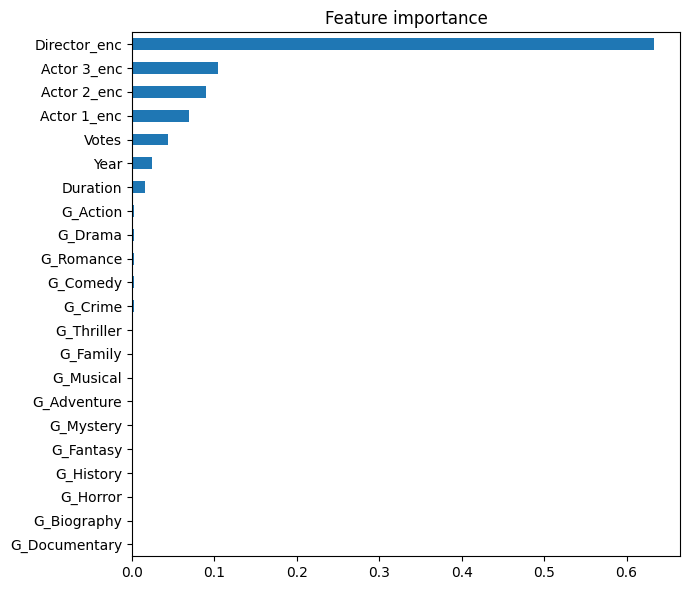

In [10]:
#9. Feature importance (Random Forest)
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(7, 6), title="Feature importance")
plt.tight_layout()
plt.show()

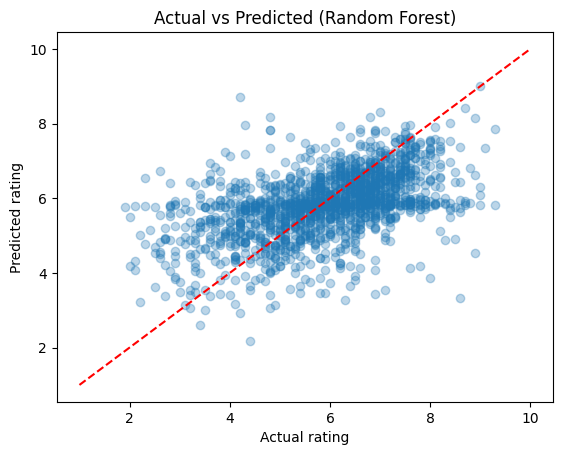

In [11]:
#10. Actual vs predicted
pred = rf.predict(X_test)
plt.scatter(y_test, pred, alpha=0.3)
plt.plot([1, 10], [1, 10], "r--")
plt.xlabel("Actual rating")
plt.ylabel("Predicted rating")
plt.title("Actual vs Predicted (Random Forest)")
plt.show()